# Betting Against Beta — Part A: Section 1, Betas With Information Available at the Time

**Idea in four steps**
1. For every stock and month end *t*, regress the stock's excess return on the market's excess return over the trailing *W* months in which the stock has a return. The slope is the beta.
2. At month end *t*, rank the eligible stocks by beta and split them into 10 equal-count groups (decile 1 = lowest beta, 10 = highest).
3. Hold each decile, value-weighted by market cap at *t*, during month *t+1*.
4. Summarize each decile: pre- and post-ranking beta, mean excess return, alpha, Treynor and information ratios.

**No look-ahead:** the beta used at *t* contains data only through *t*; the return measured is *t+1*.

**Data and conventions (from the brief).** We use the supplied **delisting-adjusted returns** (`ret`). Excess returns subtract Ken French's `RF`, and the market is `Mkt-RF`. Eligible stocks at *t* have a beta, positive market cap, a price, and no delisting code (`dlstcd`) at *t*. A held stock with a missing return in *t+1* earns a total return of zero (excess −RF) and keeps its weight. Months with a missing return are omitted when estimating betas. Means are annualized ×12 and volatilities ×√12; alphas are annualized with plain OLS t-statistics. **Every full-sample exhibit runs from 1966-01 to 2026-09.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import bab_core as bc
import bab_extra as bx
import bab_costs as bk

In [2]:
panel = bc.load_panel()
mkt = panel.mkt
print(f"{panel.ret.shape[1]:,} stocks, {panel.ret.shape[0]} months, "
      f"{panel.ret.index[0]:%Y-%m} to {panel.ret.index[-1]:%Y-%m}")


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

26,519 stocks, 765 months, 1963-01 to 2026-09


## 1.1 Trailing 60-month betas

Beta at month end *t* from months *t*−59 to *t*, using only months with a return, requiring at least 36. Below: each December from 1973, the number of eligible stocks with an estimate and the 10th, 50th and 90th percentiles of the estimates.

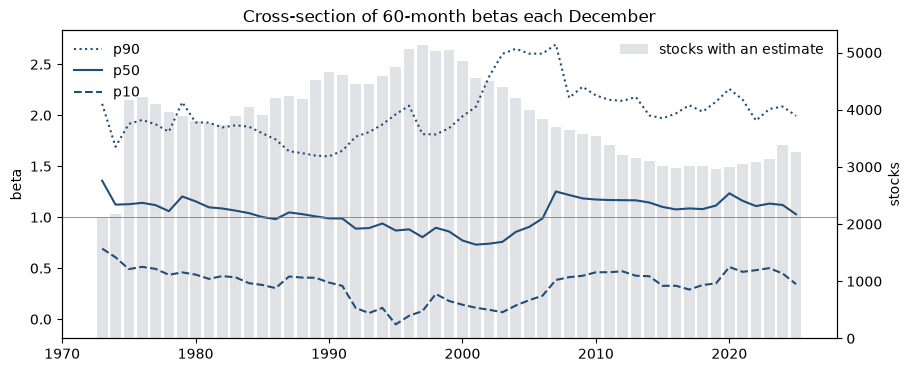

December,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
stocks,2106.00,2178.00,4173.00,4224.00,4102.00,3954.00,3896.00,3795.00,3773.00,3735.00,3889.00,4039.00,3913.00,4201.00,4233.00,4186.00,4520.00,4656.00,4603.00,4448.00,4446.00,4581.00,4740.00,5069.00,5131.00,5033.00,5039.00,4846.00,4557.00,4496.00,4404.00,4209.00,3993.00,3835.00,3701.00,3638.00,3573.00,3542.00,3375.00,3216.00,3149.00,3102.00,3018.00,2983.00,3020.00,3009.00,2968.00,2990.00,3044.00,3078.00,3145.00,3380.00,3265.00
p10,0.69,0.61,0.49,0.51,0.49,0.44,0.46,0.44,0.40,0.42,0.41,0.35,0.34,0.30,0.42,0.41,0.41,0.36,0.33,0.11,0.06,0.11,-0.05,0.03,0.08,0.25,0.18,0.14,0.11,0.09,0.07,0.13,0.19,0.23,0.38,0.41,0.43,0.46,0.46,0.47,0.43,0.42,0.33,0.33,0.29,0.34,0.35,0.51,0.46,0.48,0.50,0.45,0.34
p50,1.36,1.12,1.13,1.14,1.12,1.06,1.20,1.16,1.10,1.09,1.06,1.04,1.00,0.98,1.05,1.03,1.01,0.99,0.99,0.89,0.89,0.94,0.87,0.88,0.80,0.90,0.86,0.77,0.73,0.74,0.76,0.86,0.90,0.99,1.25,1.22,1.18,1.17,1.17,1.17,1.17,1.14,1.10,1.08,1.09,1.08,1.11,1.23,1.16,1.11,1.13,1.12,1.03
p90,2.11,1.69,1.92,1.95,1.91,1.84,2.13,1.93,1.93,1.88,1.90,1.89,1.82,1.76,1.65,1.63,1.60,1.60,1.65,1.79,1.83,1.91,2.01,2.09,1.81,1.81,1.87,1.99,2.08,2.38,2.60,2.65,2.60,2.60,2.69,2.17,2.28,2.19,2.15,2.14,2.18,2.00,1.97,2.02,2.10,2.03,2.13,2.26,2.15,1.95,2.06,2.09,1.99


In [3]:
beta60 = bc.rolling_beta(panel.ex, mkt, 60, 36)
beta36 = bc.rolling_beta(panel.ex, mkt, 36, 24)      # used in 1.3
eligible = panel.eligible

est = beta60.where(eligible)
dec = est[(est.index.month == 12) & (est.index.year >= 1973)]
t11 = pd.DataFrame({"stocks": dec.notna().sum(axis=1),
                    "p10": dec.quantile(0.10, axis=1),
                    "p50": dec.quantile(0.50, axis=1),
                    "p90": dec.quantile(0.90, axis=1)})
t11.index = t11.index.year.rename("December")

fig, ax = plt.subplots(figsize=(10, 4))
for c, style in [("p90", ":"), ("p50", "-"), ("p10", "--")]:
    ax.plot(t11.index, t11[c], ls=style, color="#1f4e79", label=c)
ax.axhline(1, color="grey", lw=0.6)
ax.set(title="Cross-section of 60-month betas each December", ylabel="beta")
ax2 = ax.twinx()
ax2.bar(t11.index, t11["stocks"], color="#8a8f98", alpha=0.25, label="stocks with an estimate")
ax2.set_ylabel("stocks"); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.legend(loc="upper left", frameon=False); ax2.legend(loc="upper right", frameon=False)
plt.show()
show(t11.T, precision=2)

The count doubles between 1974 and 1975 because Nasdaq stocks, which enter in December 1972, reach 36 months of returns. The median beta stays near one (0.73–1.36), but the spread is wide: the 10th percentile runs from about −0.05 to 0.69 and the 90th from 1.6 to 2.7. The 10th percentile sits near zero from 1992 to 2003, and the 90th–10th range is widest in 2002–2007 (about 2.3–2.5). With about 3,900 stocks a year and standard errors near 0.26 on sixty months, part of that spread is estimation noise, which is what 1.3 measures.

## 1.2 Beta-decile portfolios

From 1965-12, each month end: rank the eligible stocks on the 60-month beta, form ten equal-count groups (a stock at a breakpoint goes to the lower group), and hold each value-weighted for one month. **Pre-ranking beta** is the portfolio-weighted average of the stock betas used to sort, averaged over months. **Post-ranking beta** is the slope of the decile's realized excess return on `Mkt-RF` over the holding months. Treynor ratio = mean excess return / post-ranking beta. Information ratio = alpha / residual volatility (both annualized).

In [4]:
dec_ex, dec_pre, dec_n = bc.decile_sort(beta60, panel)


def decile_table(ex, pre):
    m = mkt.reindex(ex.index)
    rows = {}
    for g in ex:
        alpha, beta, t_alpha, _, resid, _ = bc.ols(ex[g], m)
        mean = 12 * ex[g].mean()
        rows[g] = {"pre_beta": pre[g].mean(), "post_beta": beta, "mean_excess": mean,
                   "alpha": 12 * alpha, "t_alpha": t_alpha, "treynor": mean / beta,
                   "info_ratio": 12 * alpha / (np.sqrt(12) * resid.std(ddof=2))}
    return pd.DataFrame(rows).T.rename_axis("decile")


t12 = decile_table(dec_ex, dec_pre)
premium = 12 * mkt.reindex(dec_ex.index).mean()
print(f"Holding months {dec_ex.index[0]:%Y-%m} to {dec_ex.index[-1]:%Y-%m} ({len(dec_ex)}); "
      f"stocks per decile {dec_n.min().min()}-{dec_n.max().max()}; market premium {premium:.2%}, "
      f"market Treynor ratio {premium:.2%}")
show(t12, pct=["mean_excess", "alpha", "treynor"])

Holding months 1966-01 to 2026-09 (729); stocks per decile 171-519; market premium 7.03%, market Treynor ratio 7.03%


,pre_beta,post_beta,mean_excess,alpha,t_alpha,treynor,info_ratio
decile,,,,,,,
1,0.225,0.536,6.06%,2.29%,1.848,11.30%,0.239
2,0.492,0.646,6.25%,1.71%,1.754,9.67%,0.227
3,0.680,0.758,7.81%,2.49%,2.766,10.31%,0.358
4,0.837,0.868,7.18%,1.08%,1.309,8.27%,0.169
5,0.991,0.979,7.93%,1.05%,1.332,8.10%,0.172
6,1.144,1.073,8.28%,0.74%,0.908,7.71%,0.117
7,1.314,1.195,6.69%,-1.71%,-2.061,5.59%,-0.267
8,1.520,1.299,7.25%,-1.87%,-1.909,5.58%,-0.247
9,1.811,1.493,8.56%,-1.92%,-1.301,5.74%,-0.168


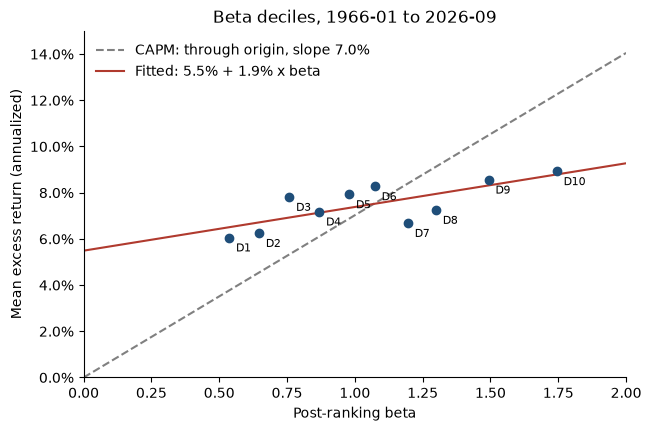

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(t12["post_beta"], t12["mean_excess"], color="#1f4e79", zorder=3)
for g, r in t12.iterrows():
    ax.annotate(f"D{g}", (r["post_beta"], r["mean_excess"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
grid = np.linspace(0, 2, 50)
a, b, *_ = bc.ols(t12["mean_excess"], t12["post_beta"])
ax.plot(grid, premium * grid, color="grey", ls="--", label=f"CAPM: through origin, slope {premium:.1%}")
ax.plot(grid, a + b * grid, color="#b03a2e", label=f"Fitted: {a:.1%} + {b:.1%} x beta")
ax.set(xlabel="Post-ranking beta", ylabel="Mean excess return (annualized)",
       title="Beta deciles, 1966-01 to 2026-09", xlim=(0, 2), ylim=(0, 0.15))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

The line is much flatter than the CAPM's. Post-ranking betas run from 0.54 to 1.74, but mean excess returns rise only from 6.1% to 8.9%, where the CAPM predicts 3.8% and 12.3%. Alphas fall from about +2% in the low deciles to −3% in D10, and the Treynor ratio falls from 11% to 5%. Pre-ranking betas (0.23 to 2.42) are far more dispersed than post-ranking betas, the first sign of estimation error. Section 2 tests this formally.

## 1.3 A 36-month window

Second beta from the trailing 36 months, requiring at least 24. Over the formation dates for holding months 1966-01 to 2026-09, we report:
- the cross-sectional Spearman correlation between the two estimates (stocks with both), averaged over dates;
- the share of stocks below the 60-month median that are also below the 36-month median;
- for deciles formed on each estimator, the slope of post- on pre-ranking decile betas.

In [6]:
dates = dec_ex.index - pd.offsets.MonthEnd(1)          # formation dates
b60, b36 = beta60.where(eligible).loc[dates], beta36.where(eligible).loc[dates]
spearman, same_side, n_both = [], [], []
for t in dates:
    both = b60.loc[t].notna() & b36.loc[t].notna()
    x, y = b60.loc[t, both], b36.loc[t, both]
    spearman.append(stats.spearmanr(x, y).statistic)
    below = x < x.median()
    same_side.append((y[below] < y.median()).mean())
    n_both.append(both.sum())

ex36, pre36, _ = bc.decile_sort(beta36, panel)
t13_deciles = decile_table(ex36, pre36)
slope = lambda t: bc.ols(t["post_beta"], t["pre_beta"])[1]

t13 = pd.Series({
    "avg Spearman correlation, 36m vs 60m": np.mean(spearman),
    "share below 60m median also below 36m median": np.mean(same_side),
    "avg stocks with both estimates": np.mean(n_both),
    "post-on-pre decile slope, 60m": slope(t12),
    "post-on-pre decile slope, 36m": slope(t13_deciles),
}).to_frame("value")
show(t13)
show(pd.DataFrame({"pre 60m": t12["pre_beta"], "post 60m": t12["post_beta"],
                   "pre 36m": t13_deciles["pre_beta"], "post 36m": t13_deciles["post_beta"]}))

,value
"avg Spearman correlation, 36m vs 60m",0.868
share below 60m median also below 36m median,0.861
avg stocks with both estimates,3584.228
"post-on-pre decile slope, 60m",0.583
"post-on-pre decile slope, 36m",0.497


,pre 60m,post 60m,pre 36m,post 36m
decile,,,,
1,0.225,0.536,0.082,0.599
2,0.492,0.646,0.407,0.654
3,0.680,0.758,0.625,0.755
4,0.837,0.868,0.805,0.860
5,0.991,0.979,0.978,0.979
6,1.144,1.073,1.151,1.078
7,1.314,1.195,1.344,1.166
8,1.520,1.299,1.585,1.308
9,1.811,1.493,1.918,1.486


**What the windows say about measurement error.** The two estimates rank stocks similarly (Spearman 0.87), and 86% of the stocks below one median are below the other. Still, the post-on-pre slope is 0.58 for the 60-month estimator but only 0.50 for the 36-month one. Pre-ranking betas from 36 months spread further (0.08 to 2.64) while post-ranking betas barely change (0.60 to 1.78), so the extra spread is noise. With $\hat\beta = \beta + e$ the slope is $\text{var}(\beta)/(\text{var}(\beta)+\text{var}(e))$. That puts the error variance at about 0.7 of the true cross-sectional variance on 60 months and about 1.0 on 36 months, a ratio of 1.4. If betas were constant, the ratio would be 60/36 ≈ 1.7. The smaller ratio is consistent with true betas drifting over time, so a longer window gains precision but also uses staler information.

**Does the evidence argue for a different window?** No. The shorter window is noisier: it sorts worse and would set leverage on more exaggerated betas. The appendix shows the slope keeps falling at 24 and 12 months (0.41 and 0.27). D1's alpha also shrinks from +2.3% at 60 months to about zero at 24–36 months and −2.8% at 12 months: a noisy sort fills the low-beta decile with stocks whose true betas are not low. The 60-month window, with shrinkage toward one, is the better default. A longer window is a Section 4 question, because the gain in precision is partly offset by staleness.

## Appendix: other windows

Value-weighted deciles over the same holding months (1966-01 to 2026-09) for shorter windows. This extends the comparison in the first version of this notebook, now with the brief's conventions.

In [7]:
windows = {"12m (min 12)": (12, 12), "24m (min 24)": (24, 24), "36m (min 24)": (36, 24), "60m (min 36)": (60, 36)}
rows = {}
for name, (w, k) in windows.items():
    ex, pre, _ = bc.decile_sort(bc.rolling_beta(panel.ex, mkt, w, k), panel)
    t = decile_table(ex, pre)
    rows[name] = {"post-on-pre slope": slope(t), "pre D1": t.loc[1, "pre_beta"], "pre D10": t.loc[10, "pre_beta"],
                  "post D1": t.loc[1, "post_beta"], "post D10": t.loc[10, "post_beta"],
                  "alpha D1": t.loc[1, "alpha"], "alpha D10": t.loc[10, "alpha"], "months": len(ex)}
show(pd.DataFrame(rows).T.astype({"months": int}), pct=["alpha D1", "alpha D10"])

,post-on-pre slope,pre D1,pre D10,post D1,post D10,alpha D1,alpha D10,months
12m (min 12),0.267,-0.638,3.392,0.820,1.741,-2.76%,-2.72%,729
24m (min 24),0.411,-0.087,2.832,0.677,1.752,-0.54%,-2.80%,729
36m (min 24),0.497,0.082,2.636,0.599,1.776,0.02%,-2.82%,729
60m (min 36),0.583,0.225,2.415,0.536,1.744,2.29%,-3.32%,729


# Betting Against Beta — Part B: Section 2 (CAPM tests) and Section 3 (default book)


In [8]:
panel = bc.load_panel()
mkt = panel.mkt
beta60 = bc.rolling_beta(panel.ex, mkt, 60, 36)      # trailing 60 months, at least 36
print(f"{panel.ret.shape[0]} months x {panel.ret.shape[1]:,} permnos, "
      f"{panel.ret.index[0]:%Y-%m} to {panel.ret.index[-1]:%Y-%m}")


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

765 months x 26,519 permnos, 1963-01 to 2026-09


## 2. What the Returns Say About the CAPM

Deciles from 1.2: ranked each month end from 1965-12 on the 60-month beta, ten equal-count groups, value-weighted, held one month. Holding months 1966-01 to 2026-09.

In [9]:
dec_ex, dec_pre, dec_n = bc.decile_sort(beta60, panel)


def decile_table(ex, pre):
    m = mkt.reindex(ex.index)
    rows = {}
    for g in ex:
        alpha, beta, t_alpha, _, _, _ = bc.ols(ex[g], m)
        rows[g] = {"mean_excess": 12 * ex[g].mean(), "pre_beta": pre[g].mean(),
                   "post_beta": beta, "alpha": 12 * alpha, "t_alpha": t_alpha}
    return pd.DataFrame(rows).T.rename_axis("decile")


def cross_section(table, premium):
    out = {}
    for x in ["post_beta", "pre_beta"]:
        a, b, t_a, t_b, _, r2 = bc.ols(table["mean_excess"], table[x])
        out[x] = {"intercept": a, "t_intercept": t_a, "slope": b, "t_slope": t_b,
                  "R2": r2, "market_premium": premium}
    return pd.DataFrame(out).T.rename_axis("regressor")


def h_stat(ex):
    # H = T [1 + SR_m^2]^-1 alpha' Sigma^-1 alpha ~ chi2(n); monthly alphas, Sigma = residual covariance (/T)
    m = mkt.reindex(ex.index)
    fits = [bc.ols(ex[g], m) for g in ex]
    alpha = np.array([f[0] for f in fits])
    resid = np.column_stack([f[4] for f in fits])
    T = len(ex)
    sigma = resid.T @ resid / T
    sr = m.mean() / m.std()
    H = T / (1 + sr**2) * alpha @ np.linalg.solve(sigma, alpha)
    return H, stats.chi2.sf(H, len(alpha))


full = decile_table(dec_ex, dec_pre)
premium = 12 * mkt.reindex(dec_ex.index).mean()
print(f"Value-weighted beta deciles, 1966-01 to 2026-09; sample market premium {premium:.2%} a year")
show(full, pct=["mean_excess", "alpha"])

Value-weighted beta deciles, 1966-01 to 2026-09; sample market premium 7.03% a year


,mean_excess,pre_beta,post_beta,alpha,t_alpha
decile,,,,,
1,6.06%,0.225,0.536,2.29%,1.848
2,6.25%,0.492,0.646,1.71%,1.754
3,7.81%,0.680,0.758,2.49%,2.766
4,7.18%,0.837,0.868,1.08%,1.309
5,7.93%,0.991,0.979,1.05%,1.332
6,8.28%,1.144,1.073,0.74%,0.908
7,6.69%,1.314,1.195,-1.71%,-2.061
8,7.25%,1.520,1.299,-1.87%,-1.909
9,8.56%,1.811,1.493,-1.92%,-1.301


### 2.1 Cross-sectional regression

Ten decile mean excess returns regressed on their betas with an intercept, 1966-01 to 2026-09. Intercept, slope and premium are annualized.

In [10]:
show(cross_section(full, premium), pct=["intercept", "slope", "market_premium"])

,intercept,t_intercept,slope,t_slope,R2,market_premium
regressor,,,,,,
post_beta,5.49%,8.127,1.89%,3.134,0.551,7.03%
pre_beta,6.21%,13.837,1.13%,3.261,0.571,7.03%


### 2.2 Joint test on the ten alphas, and sub-periods

In [11]:
periods = {"1966-01 to 2026-09": (None, None),
           "1966-01 to 2013-12": (None, "2013-12"),
           "2014-01 to 2026-09": ("2014-01", None)}

cs_rows, h_rows = [], {}
for name, (start, end) in periods.items():
    ex, pre = dec_ex.loc[start:end], dec_pre.loc[start:end]
    prem = 12 * mkt.reindex(ex.index).mean()
    cs_rows.append(cross_section(decile_table(ex, pre), prem).assign(period=name))
    H, p = h_stat(ex)
    h_rows[name] = {"H": H, "p_value": p, "months": len(ex)}

show(pd.concat(cs_rows).reset_index().set_index(["period", "regressor"]),
     pct=["intercept", "slope", "market_premium"])
show(pd.DataFrame(h_rows).T.astype({"months": int}).rename_axis("period"))

,H,p_value,months
period,,,
1966-01 to 2026-09,14.941,0.134,729
1966-01 to 2013-12,14.520,0.151,576
2014-01 to 2026-09,5.344,0.867,153


### 2.3 Shrinking the sort beta

Regress the post-ranking decile betas on the pre-ranking decile betas (full sample) to get *w*. Then re-form the deciles on $\beta^* = w\hat\beta + (1-w)$.

In [12]:
w_hat = bc.ols(full["post_beta"], full["pre_beta"])[1]
star_ex, star_pre, _ = bc.decile_sort(bc.shrink(beta60, w_hat), panel)
star = decile_table(star_ex, star_pre)

print(f"slope of post- on pre-ranking decile betas: w = {w_hat:.3f}")
print(f"largest difference in decile returns after re-forming: {(star_ex - dec_ex).abs().max().max():.1e}")

compare = pd.concat({"raw 60m beta": cross_section(full, premium),
                     "shrunk beta*": cross_section(star, premium)}, names=["sort"])
show(compare, pct=["intercept", "slope", "market_premium"])
show(pd.DataFrame({"pre_beta raw": full["pre_beta"], "pre_beta shrunk": star["pre_beta"],
                   "post_beta raw": full["post_beta"], "post_beta shrunk": star["post_beta"]}))
print(f"H raw = {h_stat(dec_ex)[0]:.2f}, H shrunk = {h_stat(star_ex)[0]:.2f}")

slope of post- on pre-ranking decile betas: w = 0.583
largest difference in decile returns after re-forming: 0.0e+00


,pre_beta raw,pre_beta shrunk,post_beta raw,post_beta shrunk
decile,,,,
1,0.225,0.549,0.536,0.536
2,0.492,0.704,0.646,0.646
3,0.680,0.813,0.758,0.758
4,0.837,0.905,0.868,0.868
5,0.991,0.994,0.979,0.979
6,1.144,1.084,1.073,1.073
7,1.314,1.183,1.195,1.195
8,1.520,1.303,1.299,1.299
9,1.811,1.473,1.493,1.493


H raw = 14.94, H shrunk = 14.94


**What changes and what does not.** $\beta^*$ is an increasing linear function of $\hat\beta$ (w ≈ 0.58 > 0), so every stock keeps its rank. The deciles hold the same stocks with the same weights, so their returns, post-ranking betas, alphas and H are identical, and so is the 2.1 regression on post-ranking betas. Only the pre-ranking betas change: each one is pulled toward one, which moves them close to the post-ranking betas. In the regression on pre-ranking betas, the slope is divided by *w* (1.1% becomes 1.9%, about the post-ranking slope) and the intercept falls (6.2% to 5.4%). The R² and t-statistics do not change, because a linear rescaling of the regressor does not change the fit. Shrinkage corrects the *scale* of the beta estimates, which matters for leverage in Section 3, but not the sort. Since *w* is estimated on the whole sample, this is an in-sample diagnostic only.

### 2.4 Discussion

The CAPM predicts that the decile points lie on a line through the origin with slope equal to the market premium (7.0% a year, 1966-01 to 2026-09). Against post-ranking betas, the fitted line has an intercept of 5.5% (t = 8.1) and a slope of 1.9% (t = 3.1). A zero-beta portfolio earns most of what the market earns, and each unit of beta adds about a quarter of the premium. Mean excess returns rise only from 6.1% (D1, beta 0.54) to 8.9% (D10, beta 1.74), where the CAPM predicts 3.8% and 12.3%. Alphas are positive in the low deciles and negative in the high ones.

The joint test is weaker than the picture. H = 14.9 (p = 0.13), so the ten value-weighted alphas are not jointly rejected: the individual alphas are only ±2–3% a year, and the deciles' residuals are highly correlated. The sub-periods differ sharply. From 1966 to 2013 the line is essentially flat (slope 0.2%, t = 0.3, against a 5.7% premium). From 2014 the slope is 8.1% (t = 6.8) against a 11.9% premium, and H is 5.3 (p = 0.87). That later window is only twelve years and nine months, so its estimates are imprecise.

Measurement error works against finding a flat line. Pre-ranking betas span 0.23 to 2.42, but post-ranking betas only 0.54 to 1.74 (slope of post on pre: 0.58). Sorting on noisy estimates puts negative errors in D1 and positive errors in D10. A regression on pre-ranking betas is therefore attenuated (slope 1.1%), while post-ranking betas avoid that bias, and the line is still flat.

The evidence supports this: in US stocks, the reward per unit of beta has been far below the CAPM premium, mainly before 2014. The sample cannot establish four things. First, whether this is mispricing or compensation for a risk the CAPM omits; this is the joint hypothesis problem, and the market proxy is US equity only. Second, a decisive joint rejection of zero alphas for value-weighted deciles. Third, whether the steeper post-2014 line is a lasting change or noise. Fourth, whether the effect can be captured after costs and in large stocks; Sections 3 and 6 address that.

## 3. The Default Book

Beta: trailing 60 months (at least 36), combined with one at *w* = 0.6, i.e. $\beta = 0.6\hat\beta_{60} + 0.4$. Each month end, the eligible stocks are ranked on that beta and split at the median rank: the lower half is long, the upper half short, and with an odd count the middle stock goes long. Weights within each leg are rank weights $\propto |z_i - \bar z|$. Each leg is scaled to an ex-ante beta of one by its weighted-average beta. The cash remainder, $1 - 1/\beta_L + 1/\beta_H$, earns the bill rate. Holding months 1966-01 to 2026-09.

$$\tilde r_{\text{book},t+1} = \frac{1}{\beta_{L,t}}\tilde r_{L,t+1} - \frac{1}{\beta_{H,t}}\tilde r_{H,t+1}$$

In [13]:
combined = bc.shrink(beta60, 0.6)
book = bc.build_book(combined, panel)
print(f"months: {len(book)}, {book.index[0]:%Y-%m} to {book.index[-1]:%Y-%m}")
print(f"months losing more than capital (failure rule): {int(book['failed'].sum())}")

months: 729, 1966-01 to 2026-09
months losing more than capital (failure rule): 0


### 3.1 Leverage and cash

,median,min,max,min_date,max_date
beta_L,0.69,0.32,0.89,1996-07,1974-06
beta_H,1.57,1.29,2.00,1990-06,2007-11
lev_L,1.45,1.12,3.15,1974-06,1996-07
lev_H,0.64,0.50,0.77,2007-11,1990-06
cash,0.19,-1.51,0.51,1996-07,1975-03
n_L,1880.00,858.00,2594.00,1969-04,1997-06
n_H,1879.00,857.00,2593.00,1969-04,1997-06


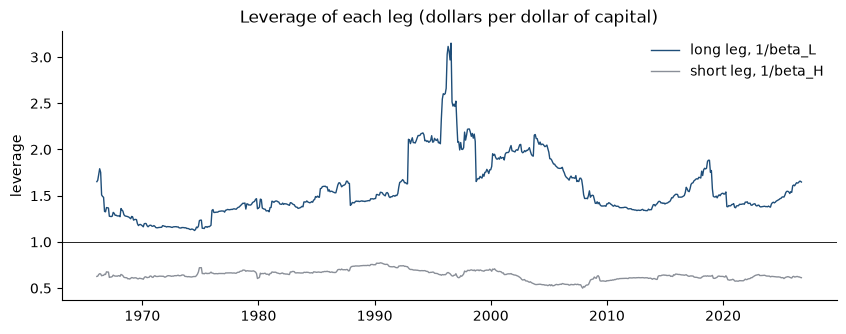

In [14]:
cols = ["beta_L", "beta_H", "lev_L", "lev_H", "cash", "n_L", "n_H"]
summary = book[cols].agg(["median", "min", "max"]).T
summary["min_date"] = [book[c].idxmin().strftime("%Y-%m") for c in cols]
summary["max_date"] = [book[c].idxmax().strftime("%Y-%m") for c in cols]
show(summary, precision=2)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(book.index, book["lev_L"], color="#1f4e79", lw=1, label="long leg, 1/beta_L")
ax.plot(book.index, book["lev_H"], color="#8a8f98", lw=1, label="short leg, 1/beta_H")
ax.axhline(1, color="black", lw=0.6)
ax.set(title="Leverage of each leg (dollars per dollar of capital)", ylabel="leverage")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 3.2 Performance

The book's return is a self-financing excess return. Each leg is shown **unlevered**, as its own excess return held long. Drawdowns are measured on the compounded path of each excess return. 1966-01 to 2026-09.

In [15]:
perf = pd.DataFrame({"book": bc.performance(book["book"], mkt),
                     "long leg (low beta), unlevered": bc.performance(book["r_L"], mkt),
                     "short leg (high beta), unlevered": bc.performance(book["r_H"], mkt)}).T
show(perf, pct=["mean", "vol", "worst_month", "max_dd", "alpha"], precision=2)

,mean,vol,sharpe,sharpe_se,skew,worst_month,max_dd,dd_peak,dd_trough,alpha,t_alpha,beta,months
book,8.75%,10.87%,0.81,0.13,-0.50,-18.09%,-54.85%,2007-05,2009-10,7.37%,5.47,0.20,729
"long leg (low beta), unlevered",9.13%,14.79%,0.62,0.13,-0.44,-21.98%,-57.14%,2007-05,2009-02,3.73%,3.37,0.77,729
"short leg (high beta), unlevered",9.31%,28.14%,0.33,0.13,0.29,-32.61%,-83.51%,1968-12,1974-12,-1.15%,-0.57,1.49,729


### 3.3 Ex-ante against realized beta

In [16]:
m = mkt.reindex(book.index)
real_L, real_H = bc.ols(book["r_L"], m)[1], bc.ols(book["r_H"], m)[1]
beta_check = pd.DataFrame({
    "ex-ante beta (avg)": [book["beta_L"].mean(), book["beta_H"].mean()],
    "realized beta": [real_L, real_H],
    "leverage (avg)": [book["lev_L"].mean(), book["lev_H"].mean()],
}, index=["long leg", "short leg"])
beta_check["levered realized beta"] = beta_check["realized beta"] * beta_check["leverage (avg)"]
show(beta_check)
approx = beta_check["levered realized beta"].iloc[0] - beta_check["levered realized beta"].iloc[1]
print(f"book: ex-ante beta 0, avg-leverage approximation {approx:.2f}, "
      f"regression beta {bc.ols(book['book'], m)[1]:.2f} (2014-01 on: {bc.ols(book['book'].loc['2014':], m.loc['2014':])[1]:.2f})")

,ex-ante beta (avg),realized beta,leverage (avg),levered realized beta
long leg,0.663,0.769,1.563,1.202
short leg,1.570,1.489,0.641,0.955


book: ex-ante beta 0, avg-leverage approximation 0.25, regression beta 0.20 (2014-01 on: 0.30)


The long leg's average ex-ante beta is 0.66, but its realized beta is 0.77; the short leg's is 1.57 against a realized 1.49. Even after shrinkage toward one, the estimates overstate the spread. As a result the long leg is over-levered (1.56 × 0.77 ≈ 1.20 of market exposure) and the short leg under-levered (0.64 × 1.49 ≈ 0.95). The difference, about 0.25, is the book's leftover beta; the regression gives 0.20, because leverage varies over time rather than sitting at its average. So the book is not market-neutral after the fact: it carries a positive beta (0.30 since 2014), which is why its alpha (7.4%) is below its mean excess return (8.8%).

### 3.4 Turnover and capacity

One-way turnover is $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}|$ on signed, levered weights, unhalved. The average starts with the second formation month. Composition is the share of each leg's levered weight in stocks below the NYSE 20th percentile of market cap and in stocks priced under $5, measured at formation.

In [17]:
comp_cols = ["turnover", "small_L", "small_H", "penny_L", "penny_H"]
capacity = pd.DataFrame({"1966-01 to 2026-09": book[comp_cols].mean(),
                         "2014-01 to 2026-09": book.loc["2014":, comp_cols].mean()}).T
capacity.columns = ["one-way turnover / month", "long: below NYSE p20", "short: below NYSE p20",
                    "long: price < $5", "short: price < $5"]
show(capacity, pct=capacity.columns)

,one-way turnover / month,long: below NYSE p20,short: below NYSE p20,long: price < $5,short: price < $5
1966-01 to 2026-09,35.05%,59.11%,56.10%,21.23%,28.90%
2014-01 to 2026-09,34.41%,53.70%,47.07%,20.45%,29.13%


The book trades about 35% of capital a month (34% since 2014), or roughly four times its capital a year. More than half of each leg sits in stocks below the NYSE 20th percentile (59% long and 56% short over the full sample; 54% and 47% since 2014). A fifth of the long leg and nearly 30% of the short leg are in stocks priced under $5. Rank weights ignore size, so a micro-cap carries as much weight as a mega-cap with the same beta rank. Capacity would bind first in the short leg, where thousands of small, low-priced, high-beta names have to be borrowed and shorted, and borrow availability, fees and price impact limit the size. The long leg's micro-cap share limits it next. Section 6 prices this turnover, and a value-weighted or size-screened book (a Section 4 candidate) would show how much of the premium survives in large stocks.

# Betting Against Beta — Section 4 (One Choice, Changed) and Section 5 (Risk)

Note: Sections 4 and 5 ignore transaction costs, financing and borrow fees. 

In [18]:
panel = bx.load_panel()                               # bab_core.load_panel on Project_Beta
mkt = panel.mkt
beta60 = bc.rolling_beta(panel.ex, mkt, 60, 36)       # trailing 60 months, at least 36
combined = bc.shrink(beta60, 0.6)                     # 0.6 * beta + 0.4
print(f"{panel.ret.shape[0]} months x {panel.ret.shape[1]:,} permnos, "
      f"{panel.ret.index[0]:%Y-%m} to {panel.ret.index[-1]:%Y-%m}")

FULL = "1966-01 to 2026-09"
POST = "2014-01 to 2026-09"


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

765 months x 26,519 permnos, 1963-01 to 2026-09


## Default book: rebuild and regression check

The default book is rebuilt with `bc.build_book(combined, panel)`. Before building anything on top of it, the table below checks it against the numbers reported in Part B.

In [19]:
book_def, w_def = bc.build_book(combined, panel, return_weights=True)
m_def = mkt.reindex(book_def.index)


def realized_beta(x, start=None):
    x = x.loc[start:]
    return bc.ols(x, mkt.reindex(x.index))[1]


p_def = bc.performance(book_def["book"], mkt)
rebuilt = {
    "holding months": len(book_def),
    "failures": int(book_def["failed"].sum()),
    "long: avg ex-ante beta": book_def["beta_L"].mean(),
    "long: realized beta": realized_beta(book_def["r_L"]),
    "long: avg leverage": book_def["lev_L"].mean(),
    "short: avg ex-ante beta": book_def["beta_H"].mean(),
    "short: realized beta": realized_beta(book_def["r_H"]),
    "short: avg leverage": book_def["lev_H"].mean(),
    "book: realized beta": p_def["beta"],
    "book: realized beta from 2014": realized_beta(book_def["book"], "2014-01"),
    "book: alpha (ann.)": p_def["alpha"],
    "book: mean excess (ann.)": p_def["mean"],
    "turnover / month": book_def["turnover"].mean(),
    "turnover / month from 2014": book_def.loc["2014":, "turnover"].mean(),
    "long below NYSE p20": book_def["small_L"].mean(),
    "short below NYSE p20": book_def["small_H"].mean(),
    "long below NYSE p20 from 2014": book_def.loc["2014":, "small_L"].mean(),
    "short below NYSE p20 from 2014": book_def.loc["2014":, "small_H"].mean(),
    "long price < $5": book_def["penny_L"].mean(),
    "short price < $5": book_def["penny_H"].mean(),
}
target = [729, 0, 0.66, 0.77, 1.56, 1.57, 1.49, 0.64, 0.20, 0.30, 0.074, 0.088,
          0.35, 0.34, 0.59, 0.56, 0.54, 0.47, 0.20, 0.30]
check = pd.DataFrame({"Part B": target, "rebuilt": list(rebuilt.values())}, index=list(rebuilt))
# Part B reports two decimals; the two penny shares are given only as "about 20%" and "nearly 30%"
tol = pd.Series(0.006, index=check.index)
tol[["long price < $5", "short price < $5"]] = 0.015
check["match"] = (check["Part B"] - check["rebuilt"]).abs() <= tol
print(f"Default book, holding months {book_def.index[0]:%Y-%m} to {book_def.index[-1]:%Y-%m}")
show(check, precision=3)

Default book, holding months 1966-01 to 2026-09


,Part B,rebuilt,match
holding months,729.000,729.000,True
failures,0.000,0.000,True
long: avg ex-ante beta,0.660,0.663,True
long: realized beta,0.770,0.769,True
long: avg leverage,1.560,1.563,True
short: avg ex-ante beta,1.570,1.570,True
short: realized beta,1.490,1.489,True
short: avg leverage,0.640,0.641,True
book: realized beta,0.200,0.196,True
book: realized beta from 2014,0.300,0.297,True


The rebuilt default book reproduces Part B to two decimals on every reported number. The penny shares are checked loosely because Part B gives them only in words ("about 20%" long, "nearly 30%" short).

## 4. One Choice, Changed

### 4.1 Pre-registration

**Mechanism.** Exclusions: a size screen.

**Alternative (one book).** At each formation date *t*, remove every stock whose market cap at *t* is below the 20th percentile of market cap among NYSE stocks at *t*. Stocks at or above the breakpoint stay, whatever their exchange. The rule uses only data dated *t*. The remaining stocks are then ranked, split and weighted within the screened cross section.

**What stays fixed (identical to the default book).** The panel, the delisting-adjusted returns and the membership rule (beta, positive cap, a price, no `dlstcd` at *t*). The trailing 60-month beta (at least 36 months) on monthly excess returns, combined as 0.6·β̂ + 0.4, used both to sort and to set leverage. The median split, with the middle stock long when the count is odd. Rank weights ∝ |z − z̄|, with *z* the rank in the (screened) cross section. Leverage L_L = 1/β_L and L_H = 1/β_H from each leg's weighted-average combined beta. Cash 1 − L_L + L_H at the bill rate. One-month holding. The missing-return convention. The failure rule. The sample 1966-01 to 2026-09. No costs.

**Expectation (a prediction, not a result).** We expect dropping stocks below the NYSE 20th percentile to lower the book's alpha and Sharpe ratio, but leave alpha positive with t > 2, and to cut turnover, because part of the default premium comes from small, illiquid stocks whose betas are measured with the most error.

### 4.2 The screened book against the default

The screened book is `bc.build_book(combined, panel, screen=bx.size_screen(panel, 20))`, where `size_screen` is True when the market cap at *t* is at or above the NYSE 20th percentile at *t*. Every other argument is the same as for the default book.

In [20]:
screen20 = bx.size_screen(panel, 20)
book_scr, w_scr = bc.build_book(combined, panel, screen=screen20, return_weights=True)
books = {"default": book_def, "screened (NYSE p20)": book_scr}

for name, b in books.items():
    fails = b[b["failed"]]
    print(f"{name}: {len(b)} holding months, {b.index[0]:%Y-%m} to {b.index[-1]:%Y-%m}; "
          f"failures (book total return < -100%): {len(fails)}")
    if len(fails):
        show(fails[["book", "lev_L", "lev_H", "cash"]])

names_kept = (book_scr["n_L"] + book_scr["n_H"]) / (book_def["n_L"] + book_def["n_H"])
print(f"share of the default book's names that pass the screen: median {names_kept.median():.1%}, "
      f"range {names_kept.min():.1%} to {names_kept.max():.1%}")

default: 729 holding months, 1966-01 to 2026-09; failures (book total return < -100%): 0
screened (NYSE p20): 729 holding months, 1966-01 to 2026-09; failures (book total return < -100%): 0
share of the default book's names that pass the screen: median 43.1%, range 36.0% to 62.3%


**Performance (the table of 3.2), 1966-01 to 2026-09.** Each leg is shown **unlevered**, as its own excess return held long. Means, volatilities and alphas are annualized. Drawdowns are on the compounded path of each excess return. Alpha, its plain OLS t-statistic and the realized beta come from OLS on `Mkt-RF`.

In [21]:
def perf_table(books, start=None):
    rows = {}
    for name, b in books.items():
        b = b.loc[start:]
        rows[(name, "book")] = bc.performance(b["book"], mkt)
        rows[(name, "long leg, unlevered")] = bc.performance(b["r_L"], mkt)
        rows[(name, "short leg, unlevered")] = bc.performance(b["r_H"], mkt)
    return pd.DataFrame(rows).T.rename_axis(["construction", "series"])


perf_full = perf_table(books)
print(f"Performance, holding months {FULL}")
show(perf_full, pct=["mean", "vol", "worst_month", "max_dd", "alpha"], precision=2)

Performance, holding months 1966-01 to 2026-09


**Leverage and cash (the summary of 3.1), 1966-01 to 2026-09.** Leverage is in dollars per dollar of capital. Cash is 1 − L_L + L_H. Ex-ante leg betas and leg counts are shown alongside.

Leverage, cash, ex-ante betas and counts, holding months 1966-01 to 2026-09


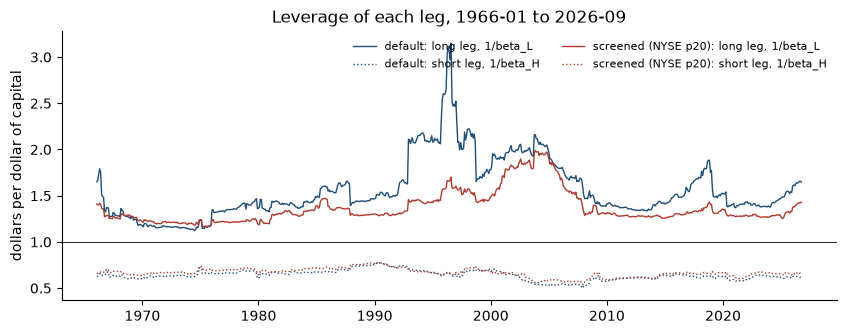

In [22]:
lev_cols = ["lev_L", "lev_H", "cash", "beta_L", "beta_H", "n_L", "n_H"]
lev_rows = {}
for name, b in books.items():
    for c in lev_cols:
        lev_rows[(name, c)] = {"median": b[c].median(), "min": b[c].min(), "min date": f"{b[c].idxmin():%Y-%m}",
                               "max": b[c].max(), "max date": f"{b[c].idxmax():%Y-%m}"}
print(f"Leverage, cash, ex-ante betas and counts, holding months {FULL}")
show(pd.DataFrame(lev_rows).T.rename_axis(["construction", "item"]), precision=2)

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, b), color in zip(books.items(), ["#1f4e79", "#b03a2e"]):
    ax.plot(b.index, b["lev_L"], color=color, lw=1, label=f"{name}: long leg, 1/beta_L")
    ax.plot(b.index, b["lev_H"], color=color, lw=1, ls=":", label=f"{name}: short leg, 1/beta_H")
ax.axhline(1, color="black", lw=0.6)
ax.set(title=f"Leverage of each leg, {FULL}", ylabel="dollars per dollar of capital")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Ex-ante against realized leg betas (as in 3.3), 1966-01 to 2026-09.** The realized beta is the slope of each unlevered leg's excess return on `Mkt-RF`. "Levered realized" multiplies it by the leg's average leverage.

In [23]:
beta_rows = {}
for name, b in books.items():
    for leg, side in [("L", "long leg"), ("H", "short leg")]:
        real = realized_beta(b[f"r_{leg}"])
        beta_rows[(name, side)] = {"avg ex-ante beta": b[f"beta_{leg}"].mean(), "realized beta": real,
                                   "realized - ex-ante": real - b[f"beta_{leg}"].mean(),
                                   "avg leverage": b[f"lev_{leg}"].mean(),
                                   "levered realized beta": real * b[f"lev_{leg}"].mean()}
print(f"Leg betas, holding months {FULL}")
show(pd.DataFrame(beta_rows).T.rename_axis(["construction", "leg"]))

Leg betas, holding months 1966-01 to 2026-09


**Turnover and composition (the table of 3.4).** One-way turnover is $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}|$ on signed, levered weights, unhalved, averaged from the second formation month. Composition is the share of each leg's weight, at formation, in stocks below the NYSE 20th percentile of market cap and in stocks priced under $5. In the screened book the below-p20 share is zero by construction.

In [24]:
comp_cols = ["turnover", "small_L", "small_H", "penny_L", "penny_H"]
comp_names = ["one-way turnover / month", "long: below NYSE p20", "short: below NYSE p20",
              "long: price < $5", "short: price < $5"]
comp = pd.concat({name: pd.DataFrame({FULL: b[comp_cols].mean(), POST: b.loc["2014":, comp_cols].mean()}).T
                  for name, b in books.items()}, names=["construction", "period"])
comp.columns = comp_names
show(comp, pct=comp_names)

**From 2014: Sharpe ratio with standard error, alpha with t-statistic, realized beta.** Holding months 2014-01 to 2026-09 (153 months, 12.75 years).

In [25]:
post_cols = ["mean", "vol", "sharpe", "sharpe_se", "alpha", "t_alpha", "beta", "months"]
post = pd.concat({"1966-01 to 2026-09": perf_full.xs("book", level="series")[post_cols],
                  "2014-01 to 2026-09": perf_table(books, "2014-01").xs("book", level="series")[post_cols]},
                 names=["period", "construction"])
show(post, pct=["mean", "vol", "alpha"], precision=2)

### 4.3 What the screen changed


In [26]:
prem = 12 * mkt.reindex(book_def.index).mean()
d, s = perf_full.loc[("default", "book")], perf_full.loc[("screened (NYSE p20)", "book")]
split = pd.DataFrame({name: {"mean": p["mean"], "alpha": p["alpha"], "beta x premium": p["beta"] * prem}
                      for name, p in [("default", d), ("screened (NYSE p20)", s)]})
split["change"] = split["screened (NYSE p20)"] - split["default"]
print(f"Book mean excess return = alpha + beta x premium, {FULL}; market premium {prem:.2%} a year")
show(split, pct=split.columns)
print(f"Sharpe: {d['sharpe']:.2f} -> {s['sharpe']:.2f}, change {s['sharpe'] - d['sharpe']:+.2f} "
      f"= {(s['sharpe'] - d['sharpe']) / d['sharpe_se']:+.1f} standard errors of one book ")

Book mean excess return = alpha + beta x premium, 1966-01 to 2026-09; market premium 7.03% a year


,default,screened (NYSE p20),change
mean,8.75%,5.52%,-3.23%
alpha,7.37%,5.44%,-1.94%
beta x premium,1.38%,0.09%,-1.29%


Sharpe: 0.81 -> 0.54, change -0.27 = -2.1 standard errors of one book 


**Where the default's leftover beta comes from.** For each leg: average ex-ante beta → realized beta (gap in brackets), then average leverage → leverage × realized beta (the leg's realized market exposure). Net = long exposure − short exposure. This approximates the book's realized beta, shown alongside from the regression. Holding months 1966-01 to 2026-09.

In [27]:
gap_rows = {}
for name in books:
    row = {}
    for side, leg in [("Long", "long leg"), ("Short", "short leg")]:
        r = beta_rows[(name, leg)]
        row[f"{side} leg: ex-ante → realized"] = (f"{r['avg ex-ante beta']:.3f} → {r['realized beta']:.3f} "
                                                  f"({r['realized - ex-ante']:+.3f})")
        row[f"{side}: avg leverage → × realized beta"] = f"{r['avg leverage']:.3f} → {r['levered realized beta']:.2f}"
    net = beta_rows[(name, "long leg")]["levered realized beta"] - beta_rows[(name, "short leg")]["levered realized beta"]
    row["Net (long − short)"] = f"{net:+.2f}"
    row["Book realized beta (regression)"] = f"{perf_full.loc[(name, 'book'), 'beta']:.2f}"
    gap_rows[name] = row
display(pd.DataFrame(gap_rows).T.rename_axis("construction"))

,Long leg: ex-ante → realized,Long: avg leverage → × realized beta,Short leg: ex-ante → realized,Short: avg leverage → × realized beta,Net (long − short),Book realized beta (regression)
construction,,,,,,
default,0.663 → 0.769 (+0.106),1.563 → 1.20,1.570 → 1.489 (-0.081),0.641 → 0.95,+0.25,0.20
screened (NYSE p20),0.741 → 0.761 (+0.020),1.369 → 1.04,1.510 → 1.504 (-0.007),0.665 → 1.00,+0.04,0.01


**4.3.** The screen weakens the case for the baseline without overturning it. 

The largest change in the reported results is the fall in the book's mean excess return, from 8.75% to 5.52% a year, which takes the Sharpe ratio from 0.81 to 0.54, about two standard errors of either estimate. Splitting the mean shows that the two parts of the fall have different causes. About 1.9 points is lost alpha (7.37% to 5.44%, t from 5.47 to 4.08). This loss in alpha means that part of the low-beta premium lives in stocks below the NYSE 20th percentile. That part is the hardest to capture because of trading costs, large percentage trades, or moving the price from a transaction. In the default, more than half of each leg sits below that size cut, and ~ 21% and 29% of the legs are priced under $5. After the screen, those penny shares are 0.7% and 3.1%. 

The other 1.3 points is market exposure the default carried without intending to, as its realized beta falls from 0.20 to 0.01. That is measurement error. Small stocks have high residual volatility, so their 60-month betas are the noisiest. Sorting on them puts the most negative errors in the long leg and the most positive in the short leg (default book: long leg 0.66 ex-ante vs 0.77 realized, short leg 1.57 ex-ante vs 1.49 realized). The default's long leg realizes 0.11 more beta than its ex-ante estimate and its short leg 0.08 less, so levering the long leg to 1/β_L (median 1.45, peak 3.15) over-levers it. In the screened book these gaps shrink to 0.02 and −0.01, the ex-ante leg betas are less extreme (0.74 and 1.51 against 0.66 and 1.57), leverage peaks at 1.99, and the book is close to market-neutral (+0.04 net compared to +0.25) after the fact. 

Our 4.1 expectation held as stated: alpha and the Sharpe ratio fell, alpha stayed positive with t = 4.08 > 2, and turnover fell. But turnover fell only from 35.1% to 32.1% a month, so the screen improves capacity mainly by changing which names are traded, not how much. And we did not foresee that the measurement-error effect would show up mostly in the realized beta rather than in alpha. After the screen, the baseline's full-sample premium is smaller but still statistically significant (alpha 5.44%, t = 4.08) and better hedged (realized beta 0.01). From 2014 neither book's alpha is distinguishable from zero (t = 0.76 default, 1.15 screened; Sharpe standard error 0.28), so that period cannot rank them.

## 5. Risk

### 5.1 Pre-registration

Two pass/fail criteria an allocator would apply to this trade. **Each criterion applies to each construction separately: the default book and the NYSE-20th-percentile screened book of Section 4.** Both are graded in 7.1. They also bind the Section 6 work done on these books. This cell is the original declaration and is not edited. Any revision goes in a second dated cell below it.

1. **Full sample, after costs.** Pass if the book's Sharpe ratio over 1966-01 to 2026-09, net of the Section 6.1 **high trading-cost schedule** (one-way cost by NYSE size quintile at formation, 100/50/30/20/10 bp, applied to $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}|$; the 50 bp financing spread is reported separately and is not deducted here), is **at least 0.40**. 
Reason: the market's own Sharpe ratio over the same months is about 0.45. A hedged, levered overlay that cannot come close to it after trading costs does not earn its complexity. With a standard error of about 0.13, 0.40 is roughly three standard errors above zero. To be decided by: the 6.1 net Sharpe, full sample.

2. **Realized beta (implementation): down-market beta.** Pass if the book's beta over the months of 1966-01 to 2026-09 with Mkt-RF < 0 (OLS with intercept on that subset, as in 5.4; point estimate) is **at most 0.25**. 
Reason: the allocator buys this book as a hedged return, so it must not lose with the market when the market falls. A down-market beta above a quarter would mean the "zero-beta" book gives back a material share of each market decline. To be decided by: the 5.4 down-market beta.

### 5.2 Drawdowns

Wealth $W_t$ is the compounded path of the book's monthly excess return, starting at 1 in 1965-12. Drawdown is $W_t / \max_{s \le t} W_s - 1$. The **peak** is the last month at the running maximum before the trough. **Recovery** is the first later month in which $W_t$ regains the peak level. **Months under water** run from the peak to the recovery month, or to 2026-09 if not recovered (marked "not recovered"). The **market's cumulative excess return** is $\prod(1 + \text{Mkt-RF}) - 1$ over the months after the peak up to and including the trough. Holding months 1966-01 to 2026-09. Recovery and months under water come from `bx.drawdown_episodes`.

The five deepest episodes of each book are shown first for context.

In [28]:
episodes = {name: bx.drawdown_episodes(b["book"], mkt) for name, b in books.items()}


def fmt_episodes(ep):
    out = ep.copy()
    for c in ["peak", "trough"]:
        out[c] = out[c].dt.strftime("%Y-%m")
    out["recovery"] = [f"{r:%Y-%m}" if ok else "not recovered" for r, ok in zip(ep["recovery"], ep["recovered"])]
    out["book lost, market rose"] = ep["mkt_peak_to_trough"] > 0
    return out.drop(columns="recovered")


print(f"Five deepest drawdowns of each book (compounded excess-return path), holding months {FULL}")
show(pd.concat({name: fmt_episodes(ep.head(5)) for name, ep in episodes.items()}, names=["construction", "rank"]),
     pct=["depth", "mkt_peak_to_trough"])

Five deepest drawdowns of each book (compounded excess-return path), holding months 1966-01 to 2026-09


**The two episodes reported for each book.** Besides each book's largest drawdown, the contrast episode is the *other* book's largest one: the episode of this book whose span from peak to recovery contains the other book's deepest trough. The group chose this pairing so that both books are shown in the same two events. The 2007–09 crisis is a loss alongside a falling market. The 1998–2000 technology run-up is a loss while the market rose. Comparing them separates losses from leftover market beta from losses the hedge does not cover.

In [29]:
deepest_trough = {name: ep.loc[0, "trough"] for name, ep in episodes.items()}
chosen = {}
for name, ep in episodes.items():
    other = next(n for n in books if n != name)
    end = ep["recovery"].fillna(book_def.index[-1])
    contrast = ep[(ep["peak"] < deepest_trough[other]) & (end >= deepest_trough[other])].iloc[0]
    chosen[(name, "largest")] = ep.loc[0]
    chosen[(name, "contrast")] = contrast
chosen = pd.DataFrame(chosen).T.rename_axis(["construction", "episode"])
print(f"Selected drawdown episodes, holding months {FULL}")
show(fmt_episodes(chosen.astype({"depth": float, "mkt_peak_to_trough": float, "recovered": bool,
                                 "months_under_water": int}).assign(
                                     peak=lambda d: pd.to_datetime(d["peak"]),
                                     trough=lambda d: pd.to_datetime(d["trough"]),
                                     recovery=lambda d: pd.to_datetime(d["recovery"]))),
     pct=["depth", "mkt_peak_to_trough"])

Selected drawdown episodes, holding months 1966-01 to 2026-09


**Where each loss came from.** Over the months after the peak through the trough, the book's monthly excess return is exactly L_L·r_L − L_H·r_H. The sums of the two contributions therefore add up to the sum of the book's monthly returns; compounded returns are shown alongside. Leverage and ex-ante betas are averages over the same months.

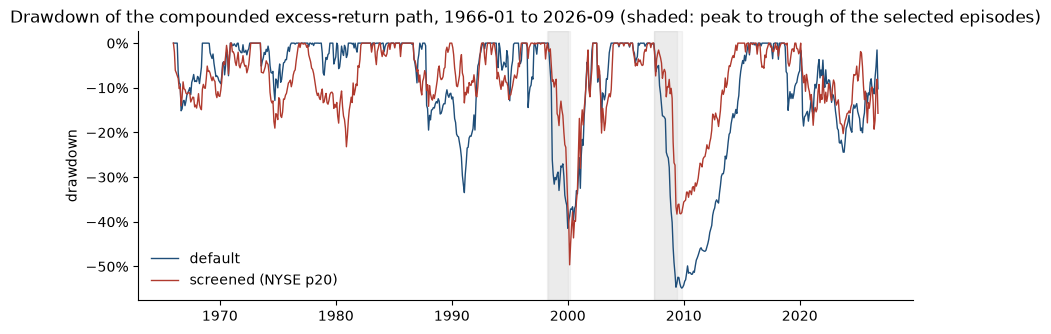

In [30]:
decomp = pd.DataFrame({key: bx.episode_decomposition(books[key[0]], mkt, row["peak"], row["trough"])
                       for key, row in chosen.iterrows()})
decomp.columns = pd.MultiIndex.from_tuples(
    [(n, f"{e}: {chosen.loc[(n, e), 'peak']:%Y-%m} to {chosen.loc[(n, e), 'trough']:%Y-%m}") for n, e in decomp.columns])
pct_rows = [r for r in decomp.index if r.startswith(("sum", "compounded"))]
display(decomp.style.format("{:.2%}", subset=pd.IndexSlice[pct_rows, :])
        .format("{:.2f}", subset=pd.IndexSlice[[r for r in decomp.index if r not in pct_rows], :]))

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, b), color in zip(books.items(), ["#1f4e79", "#b03a2e"]):
    w = bx.wealth_path(b["book"])
    ax.plot(w.index, w / w.cummax() - 1, color=color, lw=1, label=name)
for name, e in chosen.index:
    r = chosen.loc[(name, e)]
    ax.axvspan(r["peak"], r["trough"], color="grey", alpha=0.08)
ax.set(title=f"Drawdown of the compounded excess-return path, {FULL} (shaded: peak to trough of the selected episodes)",
       ylabel="drawdown")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Inside the 2007–09 episodes.** Each crisis episode is split at the market's own low within it, the month in which the compounded Mkt-RF path is lowest. This separates the crash from the rebound.

In [31]:
split_rows = {}
for name, e in [("default", "largest"), ("screened (NYSE p20)", "contrast")]:
    r = chosen.loc[(name, e)]
    m_path = (1 + mkt.loc[r["peak"]:r["trough"]].iloc[1:]).cumprod()
    m_low = m_path.idxmin()
    after_low = book_def.index[book_def.index.get_loc(m_low) + 1]
    for part, (a, z) in {f"peak to market low {m_low:%Y-%m}": (r["peak"], m_low),
                         f"{after_low:%Y-%m} to trough {r['trough']:%Y-%m}": (m_low, r["trough"])}.items():
        split_rows[(name, part)] = bx.episode_decomposition(books[name], mkt, a, z)
split_tab = pd.DataFrame(split_rows).T.rename_axis(["construction", "sub-period"])
keep = ["months", "avg lev_L", "avg lev_H", "sum long contribution L_L*r_L", "sum short contribution -L_H*r_H",
        "compounded book", "compounded r_L (unlevered)", "compounded r_H (unlevered)", "compounded Mkt-RF"]
show(split_tab[keep], pct=keep[3:], precision=2)

**5.2. Episodes.** Default book: its largest drawdown runs from 2007-05 to 2009-10 (−54.9%), recovers in 2015-07 after 98 months, and the market's excess return over it is −30.3%. Its contrast runs from 1998-04 to 1999-12 (−41.4%), recovers in 2002-02 after 46 months, with the market at +25.5%. Screened book: its largest runs from 1998-03 to 2000-02 (−49.6%), recovers in 2002-02 after 47 months, with the market at +23.4%. Its contrast runs from 2007-05 to 2009-05 (−38.3%), recovers in 2014-08 after 87 months, with the market at −38.6%. The screen reverses the ranking: it makes the crisis loss shallower (−54.9% to −38.3%) and the technology-bubble loss deeper (−41.4% to −49.6%).

**Losing while the market rose.** Both books lost in 1998–2000 while the market rose, and the five-deepest tables add the default's still-open drawdown from 2018-08 (−24.4%, market +38.9%) and the screened book's 1977-04 (−23.2%, market +40.5%) and 2020-01 (−20.3%, market +32.1%) episodes. In 1998–2000 both legs lost. The unlevered high-beta leg rose 25.4% (default) and 60.0% (screened), costing the short side 22.0 and 39.1 points (summed monthly contributions). Meanwhile the low-beta leg fell 12.1% and 17.4%, and, levered at 1.81 and 1.47, cost another 28.3 and 26.1 points. The cause is the construction itself. Hedged to zero ex-ante beta, the book is still a levered bet that low-beta stocks beat high-beta stocks per unit of beta, so it loses whenever high-beta stocks outrun their betas, whatever the market does. The screened book loses more overall because its short leg, large high-beta stocks, rose 60.0% and cost 39.1 points, against 25.4% and 22.0 points in the default.

**Losing with the market (2007–09).** The default's crisis loss has a different source. From the 2007-05 peak to the market's low in 2009-02, its long leg fell 57.1% unlevered, more than the market's 51.4%, against an average ex-ante beta of 0.67 over the episode. Levered at 1.53, the long leg cost 120.8 points, while the short gained 55.5. Then, from 2009-03 to 2009-10, the high-beta leg rebounded 137.8% and cost the short side 58.4 points. The loss came from leftover bet`a on the way down and from the short leg on the way up. The screened book had the same pattern but smaller: −26.8% in the crash and −15.7% in a three-month rebound to its 2009-05 trough.

### 5.3 Rolling beta and tail risk

The rolling beta is the OLS slope of the book's monthly excess return on Mkt-RF over the trailing 36 months, so the first value is dated 1968-12. Holding months 1966-01 to 2026-09.

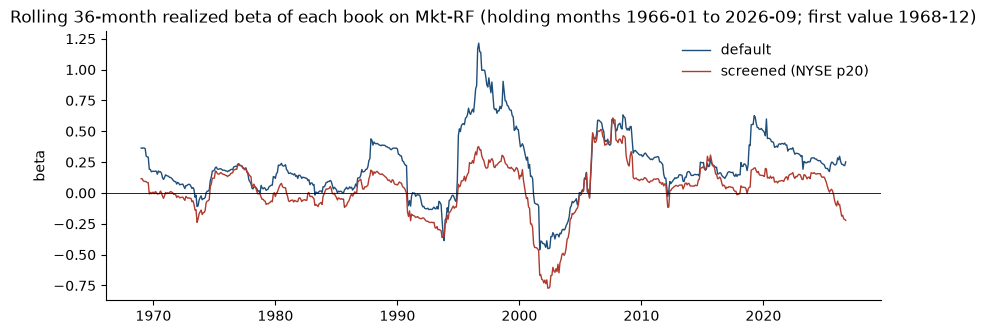

,min,min date,max,max date,median,share of windows > 0.25,windows
default,-0.46,2001-08,1.21,1996-08,0.18,36.74%,694
screened (NYSE p20),-0.77,2002-04,0.61,2007-08,0.06,9.22%,694


In [32]:
roll = pd.DataFrame({name: bx.rolling_beta_series(b["book"], mkt, 36) for name, b in books.items()})

fig, ax = plt.subplots(figsize=(10, 3.5))
for (name, s), color in zip(roll.items(), ["#1f4e79", "#b03a2e"]):
    ax.plot(s.index, s, color=color, lw=1, label=name)
ax.axhline(0, color="black", lw=0.6)
ax.set(title=f"Rolling 36-month realized beta of each book on Mkt-RF (holding months {FULL}; first value 1968-12)",
       ylabel="beta")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

roll_summary = pd.DataFrame({name: {"min": s.min(), "min date": f"{s.idxmin():%Y-%m}",
                                    "max": s.max(), "max date": f"{s.idxmax():%Y-%m}",
                                    "median": s.median(), "share of windows > 0.25": (s.dropna() > 0.25).mean(),
                                    "windows": int(s.notna().sum())}
                             for name, s in roll.items()}).T
show(roll_summary, pct=["share of windows > 0.25"], precision=2)

**Tail risk.** Monthly 5% VaR and CVaR of the book's excess return over all 729 holding months, 1966-01 to 2026-09. **VaR and CVaR are shown as returns, so a loss is negative.** Historical VaR is the 5th percentile of the monthly returns (linear interpolation). CVaR is the mean of the returns at or below it. Normal VaR is the monthly mean − 1.645 × the monthly standard deviation. Skewness and excess kurtosis are pandas `.skew()` and `.kurt()`, and normal kurtosis is 0.

In [33]:
tails = pd.DataFrame({name: bx.tail_risk(b["book"]) for name, b in books.items()}).T
tails["months"] = tails["months"].astype(int)
print(f"Monthly tail risk of the book's excess return, {FULL}")
show(tails, pct=["hist_VaR_5%", "hist_CVaR_5%", "normal_VaR_5%"], precision=2)

Monthly tail risk of the book's excess return, 1966-01 to 2026-09


,hist_VaR_5%,hist_CVaR_5%,normal_VaR_5%,skew,excess_kurtosis,months
default,-4.48%,-7.20%,-4.43%,-0.50,5.20,729
screened (NYSE p20),-4.16%,-6.80%,-4.43%,-0.49,4.04,729


**5.3.** The default book's 36-month beta ranges from −0.46 (window ending 2001-08) to 1.21 (window ending 1996-08), with a median of 0.18, and is above 0.25 in 36.7% of windows. Its maximum coincides with the long leg's peak leverage of 3.15 in 1996-07 (4.2). The screened book's beta ranges from −0.77 (2002-04) to 0.61 (2007-08), with a median of 0.06, and is above 0.25 in only 9.2% of windows. Neither book is zero-beta window by window. Both minima come in windows ending in 2001–02, which span the technology bubble and its collapse. The screen centres the beta near zero but does not remove the swings; its minimum is lower than the default's. In the tails, the monthly 5% historical VaR is −4.48% (default) and −4.16% (screened). The normal VaR is −4.43% for both, so at the 5% quantile the normal approximation is close. Beyond that quantile it is not: CVaR is −7.20% and −6.80%, skewness −0.50 and −0.49, and excess kurtosis 5.20 and 4.04. Losses beyond the 5% VaR are larger than a normal distribution implies, a little less so for the screened book.

### 5.4 Up- and down-market betas

The book's beta is estimated separately over months with Mkt-RF > 0 and months with Mkt-RF < 0, by OLS with an intercept on each subset, with plain OLS t-statistics. Alpha is annualized. Holding months 1966-01 to 2026-09.

In [34]:
updown = pd.concat({name: bx.up_down_beta(b["book"], mkt) for name, b in books.items()},
                   names=["construction", "months"])
updown["months"] = updown["months"].astype(int)
full_beta = perf_full.xs("book", level="series")["beta"]
print(f"Months with Mkt-RF exactly 0 (in neither group): {int((mkt.reindex(book_def.index) == 0).sum())}")
print("single realized beta: " + ", ".join(f"{n} {b:.2f}" for n, b in full_beta.items()))
show(updown, pct=["alpha_ann"], precision=2)

Months with Mkt-RF exactly 0 (in neither group): 0
single realized beta: default 0.20, screened (NYSE p20) 0.01


**5.4.** The default book's beta is −0.09 (t = −1.67, 433 months) when the market rises and 0.49 (t = 8.85, 296 months) when it falls. For the screened book the figures are −0.09 (t = −1.61) and 0.13 (t = 2.43). The single realized betas (0.20 default book and 0.01 screened book) average two different exposures. Neither book gains when the market rises, but the default loses about half of each market decline, so its market risk is one-sided, like a short put. That is the exposure that hurt it in 2007–09. The screen cuts the down-market beta from 0.49 to 0.13, though it remains significantly above zero. (5.1 criterion 2 is decided on these down-market betas and is applied in 7.1.)

(functions below are to create output books)

In [35]:
recipe = bx.make_books(panel)
for key, (b, w) in [("default", (book_def, w_def)), ("screened", (book_scr, w_scr))]:
    rb, rw = recipe[key]
    pd.testing.assert_frame_equal(rb, b)
    pd.testing.assert_frame_equal(rw, w)
print("bx.make_books reproduces both books and their weights exactly")

bx.make_books reproduces both books and their weights exactly


In [36]:
out_dir = bx.DATA_DIR / "output"
out_dir.mkdir(exist_ok=True)
for key, (b, w) in recipe.items():
    b.to_csv(out_dir / f"book_{key}.csv", date_format="%Y-%m-%d")
    w.to_parquet(out_dir / f"weights_{key}.parquet", index=False)
    print(f"{key}: {len(b)} holding months ({b.index[0]:%Y-%m} to {b.index[-1]:%Y-%m}), "
          f"{len(w):,} weight rows -> output/book_{key}.csv, output/weights_{key}.parquet")

reloaded = pd.read_csv(out_dir / "book_screened.csv", index_col="date", parse_dates=True)
print(f"round-trip check, screened book return: max abs difference "
      f"{(reloaded['book'] - recipe['screened'][0]['book']).abs().max():.1e}")

default: 729 holding months (1966-01 to 2026-09), 2,616,498 weight rows -> output/book_default.csv, output/weights_default.parquet
screened: 729 holding months (1966-01 to 2026-09), 1,179,014 weight rows -> output/book_screened.csv, output/weights_screened.parquet
round-trip check, screened book return: max abs difference 9.9e-17


# Betting Against Beta — Section 6 (Cost and Persistence) and Section 7 (Recommendation) 

**Costs.** Each name traded at formation date *t* is placed in an NYSE size quintile at *t*. The breakpoints are the 20th, 40th, 60th and 80th percentiles of market cap among NYSE names with positive cap at *t*. Every name, whatever its exchange, is placed by them, and a name at a breakpoint goes to the upper quintile, as in the Section 4 screen. The month's cost is $\sum_i |w_{i,t} - w^{\text{drift}}_{i,t-1}| \times c(q_i)$, on the same signed, levered weights and drift as the 3.4 turnover. It is charged to the holding month *t+1*, so the net return is the book's excess return minus that cost. Two choices are ours:
- The first formation month (1965-12) is charged for the initial purchase (drifted weight zero). The 3.4 turnover average leaves it out.
- A name sold at *t* that has no positive cap at *t* (for example, one that delisted) takes its quintile from *t*−1, the last date it was held.


In [37]:
panel = bx.load_panel()                               # bab_core.load_panel on Project_Beta/data
mkt = panel.mkt
recipe = bx.make_books(panel)                         # {"default": (book, weights), "screened": (book, weights)}
names = {"default": "default", "screened": "screened (NYSE p20)"}
books = {names[k]: b for k, (b, _) in recipe.items()}
weights = {names[k]: w for k, (_, w) in recipe.items()}

FULL, PRE, POST = "1966-01 to 2026-09", "1966-01 to 2013-12", "2014-01 to 2026-09"
periods = {FULL: (None, None), PRE: (None, "2013-12"), POST: ("2014-01", None)}

out_dir = bx.DATA_DIR / "output"
for k, b in recipe.items():
    saved = pd.read_csv(out_dir / f"book_{k}.csv", index_col="date", parse_dates=True)
    print(f"{names[k]}: {len(b[0])} holding months, {b[0].index[0]:%Y-%m} to {b[0].index[-1]:%Y-%m}; "
          f"max abs difference from output/book_{k}.csv: {(saved['book'] - b[0]['book']).abs().max():.1e}")


def show(df, pct=(), precision=3):
    display(df.style.format({c: "{:.2%}" for c in pct}, precision=precision))

default: 729 holding months, 1966-01 to 2026-09; max abs difference from output/book_default.csv: 9.9e-17
screened (NYSE p20): 729 holding months, 1966-01 to 2026-09; max abs difference from output/book_screened.csv: 9.9e-17


## Traded weight by NYSE size quintile

`bk.traded_by_quintile` rebuilds each month's trades from the signed levered weights, using the drift and rescaling of `build_book`. It checks that their total equals the 3.4 turnover in every month from the second formation date. The table reports the average traded weight per month in each quintile, as a share of capital, and each quintile's share of all trading.

In [38]:
traded, info = {}, {}
for name, b in books.items():
    traded[name], info[name] = bk.traded_by_quintile(weights[name], panel, book=b)
print("rebuilt trades match build_book turnover in every month (checked inside traded_by_quintile)")
show(pd.DataFrame(info).T, pct=["their share of all traded weight"])

rows = {}
for name, tr in traded.items():
    for per, (a, z) in [(FULL, (None, None)), (POST, ("2014-01", None))]:
        t = tr.loc[a:z]
        r = t.mean()
        rows[(name, per, "traded / month")] = r
        rows[(name, per, "share of trading")] = r / r["total"]
by_q = pd.DataFrame(rows).T.rename_axis(["construction", "period", "measure"])
by_q.columns = ["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest", "total"]
show(by_q, pct=by_q.columns)

for k, name in names.items():
    traded[name].to_csv(out_dir / f"traded_by_quintile_{k}.csv", date_format="%Y-%m-%d")

rebuilt trades match build_book turnover in every month (checked inside traded_by_quintile)


,trades taking the t-1 quintile,their share of all traded weight
default,1378.000,0.36%
screened (NYSE p20),149.000,0.09%


## 6. Cost and Persistence

### 6.1 Costs, financing and break-even

**High schedule:** one-way cost 100 / 50 / 30 / 20 / 10 bp per unit of traded weight, smallest to largest NYSE quintile. Cost per year is 12 × the mean monthly cost. The net Sharpe ratio is that of the monthly excess return minus the month's cost.

**Financing:** a 50 bp annual spread on the notional $(L_L-1)^+ + L_H$, the amount borrowed for the long leg plus the short proceeds, charged monthly as $0.005/12 \times$ notional. As 5.1 specifies, it is reported separately and is not deducted in criterion 1. The last column, net of both, is for the 7.2 discussion only.

In [39]:
cost_high = {name: bk.trading_cost(traded[name], bk.HIGH) for name in books}
fin = {name: bk.financing_drag(b) for name, b in books.items()}


def sharpe(x):
    return np.sqrt(12) * x.mean() / x.std()


rows = {}
for name, b in books.items():
    for per in [FULL, POST]:
        a, z = periods[per]
        g, c, f = b["book"].loc[a:z], cost_high[name].loc[a:z], fin[name].loc[a:z]
        notional = (b["lev_L"] - 1).clip(lower=0).loc[a:z] + b["lev_H"].loc[a:z]
        rows[(name, per)] = {
            "gross mean": 12 * g.mean(), "high-schedule cost / yr": 12 * c.mean(), "net mean": 12 * (g - c).mean(),
            "gross Sharpe": sharpe(g), "net Sharpe (high)": sharpe(g - c),
            "avg financing notional": notional.mean(), "financing drag / yr": 12 * f.mean(),
            "net Sharpe (high + financing)": sharpe(g - c - f), "months": len(g)}
costs = pd.DataFrame(rows).T.rename_axis(["construction", "period"])
costs["months"] = costs["months"].astype(int)
show(costs, pct=["gross mean", "high-schedule cost / yr", "net mean", "financing drag / yr"], precision=2)

by_q_cost = pd.DataFrame({name: 12 * traded[name][bk.QUINTILES].mean() * bk.HIGH for name in books}).T
by_q_cost.columns = ["Q1 smallest", "Q2", "Q3", "Q4", "Q5 largest"]
by_q_cost["total"] = by_q_cost.sum(axis=1)
print(f"High-schedule cost per year by NYSE size quintile, {FULL}")
show(by_q_cost, pct=by_q_cost.columns)

High-schedule cost per year by NYSE size quintile, 1966-01 to 2026-09


,Q1 smallest,Q2,Q3,Q4,Q5 largest,total
default,2.81%,0.27%,0.11%,0.06%,0.03%,3.26%
screened (NYSE p20),0.36%,0.78%,0.24%,0.13%,0.05%,1.55%


**Break-even, 1966-01 to 2026-09.** The uniform one-way cost per unit traded at which the full-sample mean net return is zero is $c^* = \bar r_{\text{book}} / \overline{\text{traded}}$. The multiple of the high schedule that does the same is $k^* = \bar r_{\text{book}} / \overline{\text{cost}}_{\text{high}}$. The high schedule's own average cost per unit traded, $\overline{\text{cost}}_{\text{high}} / \overline{\text{traded}}$, is shown beside $c^*$. Trading costs only.

In [40]:
be = pd.DataFrame({name: bk.break_even(b, traded[name], bk.HIGH) for name, b in books.items()}).T
show(be, pct=["mean gross excess (ann.)", "traded weight / month", "schedule cost per unit traded",
              "break-even uniform cost per unit traded"], precision=2)
print("in basis points per unit traded: " + "; ".join(
    f"{n}: schedule {1e4 * r['schedule cost per unit traded']:.0f} bp vs break-even "
    f"{1e4 * r['break-even uniform cost per unit traded']:.0f} bp" for n, r in be.iterrows()))

,mean gross excess (ann.),traded weight / month,schedule cost per unit traded,break-even uniform cost per unit traded,break-even multiple of schedule
default,8.75%,35.32%,0.77%,2.06%,2.68
screened (NYSE p20),5.52%,32.30%,0.40%,1.42%,3.56


in basis points per unit traded: default: schedule 77 bp vs break-even 206 bp; screened (NYSE p20): schedule 40 bp vs break-even 142 bp


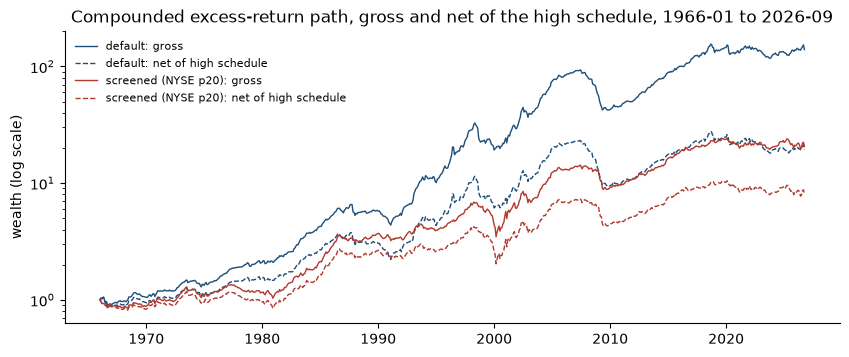

In [41]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for (name, b), color in zip(books.items(), ["#1f4e79", "#b03a2e"]):
    ax.plot(bx.wealth_path(b["book"]), color=color, lw=1, label=f"{name}: gross")
    ax.plot(bx.wealth_path(b["book"] - cost_high[name]), color=color, lw=1, ls="--", label=f"{name}: net of high schedule")
ax.set_yscale("log")
ax.set(title=f"Compounded excess-return path, gross and net of the high schedule, {FULL}", ylabel="wealth (log scale)")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**6.1.** Under the high schedule, trading costs take 3.26% a year from the default book and 1.55% from the screened book over 1966-01 to 2026-09 (3.01% and 1.40% from 2014). The full-sample Sharpe ratio falls from 0.81 to 0.51 for the default and from 0.54 to 0.39 for the screened book. From 2014 both fall to 0.25.

The default pays twice as much for a reason the composition in 3.4 already pointed to. Two-thirds of its trading (66%; 60% from 2014) is in the smallest NYSE quintile, at 100 bp, so its average cost is 77 bp per unit traded. The screened book's average is 40 bp, with 40% of its trading in the second quintile at 50 bp. It still does 9% of its trading in the smallest quintile, 0.36% a year of its 1.55%. These are sales of names that fell below the NYSE 20th percentile since the last formation date. A size screen forces the book to trade at the worst cost precisely when a name leaves it.

The 50 bp financing spread adds 0.60% a year for the default (average notional 1.20) and 0.52% for the screened book (1.03). Net of both, the Sharpe ratios are 0.45 and 0.34.

**Against the break-even, the schedule is well inside it.** The default would need a uniform cost of 206 bp per unit traded, or 2.68 times the high schedule, before its full-sample mean net return reached zero. The screened book would need 142 bp, or 3.56 times. Neither book is close to losing money after costs. The question costs raise is whether what is left is enough, and that is what criterion 1 tests. For the default, the margin is in the quintile where the illustrative 100 bp is least reliable, since 21% of its long leg and 29% of its short leg are priced under $5. Borrow fees on the short leg are not in either number.

### 6.2 Persistence: before and from 2014

For each book over 1966-01 to 2013-12 and 2014-01 to 2026-09: the gross Sharpe ratio with its standard error, alpha with its t-statistic, realized beta, and the net Sharpe ratio under the high schedule. The full sample is shown for reference.

Three diagnostics follow, all from the standard errors. Because the two windows do not overlap, their Sharpe estimates are treated as independent.
- $SR/se$ for each window: how far each Sharpe ratio is from zero.
- $(SR_{\text{post}} - SR_{\text{pre}})/\sqrt{se_{\text{pre}}^2 + se_{\text{post}}^2}$: whether the later window differs from the earlier one.
- The mean split into alpha + beta × the window's market premium, which is exact for OLS. It shows how much of each window's return is market exposure.

In [42]:
rows = {}
for name, b in books.items():
    for per, (a, z) in periods.items():
        g = b["book"].loc[a:z]
        p = bc.performance(g, mkt)
        prem = 12 * mkt.reindex(g.index).mean()
        rows[(name, per)] = {"sharpe": p["sharpe"], "sharpe_se": p["sharpe_se"], "SR / se": p["sharpe"] / p["sharpe_se"],
                             "alpha": p["alpha"], "t_alpha": p["t_alpha"], "beta": p["beta"],
                             "net Sharpe (high)": sharpe(g - cost_high[name].loc[a:z]),
                             "mean": p["mean"], "beta x premium": p["beta"] * prem, "market premium": prem,
                             "months": int(p["months"])}
persist = pd.DataFrame(rows).T.rename_axis(["construction", "period"])
show(persist, pct=["alpha", "mean", "beta x premium", "market premium"], precision=2)

diff = {}
for name in books:
    pre, post = persist.loc[(name, PRE)], persist.loc[(name, POST)]
    se = np.hypot(pre["sharpe_se"], post["sharpe_se"])
    diff[name] = {"SR post - SR pre": post["sharpe"] - pre["sharpe"], "se of difference": se,
                  "z": (post["sharpe"] - pre["sharpe"]) / se,
                  "years for post-2014 SR to sit 2 se from 0": 4 * (1 + post["sharpe"]**2 / 24) / post["sharpe"]**2}
show(pd.DataFrame(diff).T, precision=2)

,SR post - SR pre,se of difference,z,years for post-2014 SR to sit 2 se from 0
default,-0.30,0.32,-0.94,12.80
screened (NYSE p20),-0.16,0.32,-0.52,24.69


**6.2.** **Before 2014 the evidence is strong.** Over 48 years the default book's Sharpe ratio is 0.86 (standard error 0.15), with alpha 8.65% (t = 5.49). The screened book's is 0.57 (0.15), with alpha 5.99% (t = 3.90). Net of the high schedule they are 0.57 and 0.42.

**From 2014 the Sharpe ratios are 0.56 and 0.40, but with standard errors of 0.28.** Twelve years and nine months is a quarter of the earlier window, so the standard error is about twice as large. Even the default's gross Sharpe ratio sits only 2.0 standard errors from zero, and much of it is not the low-beta premium. Its 5.38% mean splits into 1.85% alpha (t = 0.76) and 3.52% from its realized beta of 0.30 times a market premium of 11.87%, the highest of any window here. The screened book has almost no beta (0.06), so its 3.70% is mostly alpha (3.02%), but with t = 1.15. Net of costs, both books' post-2014 Sharpe ratios are 0.25, under one standard error from zero.

**What the period since 2014 can establish is limited.** It shows the trade did not lose money gross. It cannot establish that the premium persisted: neither alpha is distinguishable from zero. It also cannot establish that the premium declined. The fall from the pre-2014 Sharpe ratio is 0.30 (default) and 0.16 (screened), only −0.94 and −0.52 standard errors of the difference. The two windows are statistically compatible. A Sharpe ratio of 0.56 would need about 13 years to sit two standard errors from zero, and 0.40 about 25 years, so this window could not have settled the question either way. The case for the strategy therefore rests on the pre-2014 window. The recent window is consistent both with a smaller premium continuing and with no premium at all.

## 7. Recommendation

### 7.1 The 5.1 criteria

As declared in 5.1, before any Section 5 or 6 result was computed, and applied to each construction separately:
1. **Full sample, after costs:** Sharpe ratio over 1966-01 to 2026-09, net of the 6.1 high trading-cost schedule (financing not deducted), **at least 0.40**.
2. **Down-market beta:** beta over the months of 1966-01 to 2026-09 with Mkt-RF < 0 (OLS with intercept, as in 5.4; point estimate), **at most 0.25**.

In [43]:
grade = {}
for name, b in books.items():
    net_sr = costs.loc[(name, FULL), "net Sharpe (high)"]
    down = bx.up_down_beta(b["book"], mkt).loc["down (Mkt-RF < 0)"]
    grade[(name, "1. full-sample net Sharpe (high) >= 0.40")] = {"value": net_sr, "threshold": 0.40, "pass": net_sr >= 0.40}
    grade[(name, "2. down-market beta <= 0.25")] = {"value": down["beta"], "threshold": 0.25, "pass": down["beta"] <= 0.25,
                                                     "t": down["t_beta"], "months": int(down["months"])}
grade = pd.DataFrame(grade).T.rename_axis(["construction", "criterion"])
show(grade, precision=3)
for name in books:
    print(f"{name}: {'PASSES' if grade.loc[name, 'pass'].all() else 'FAILS'} the 5.1 criteria "
          f"({int(grade.loc[name, 'pass'].sum())} of 2)")

default: FAILS the 5.1 criteria (1 of 2)
screened (NYSE p20): FAILS the 5.1 criteria (1 of 2)


**7.1.** **Both constructions fail, each on a different criterion.**
- *Default book:* criterion 1 passes (net Sharpe 0.506 ≥ 0.40), but criterion 2 fails. Its down-market beta of 0.49 (t = 8.85, 296 months) is about twice the 0.25 limit.
- *Screened book:* criterion 2 passes (0.13), but criterion 1 fails. Its net Sharpe of 0.385 is 0.015 short of 0.40, about a tenth of the 0.13 standard error. That is not a meaningful statistical difference. But the threshold was fixed before the result was seen, so it is reported as a fail and the criteria are not revised.

The overall decisions agree (neither passes), but the failures are of different kinds. If one construction had to be run, we would prefer the screened book. Its failure is a narrow miss on the size of the return. The default's is structural: it loses about half of each market decline, the exposure behind its −54.9% drawdown in 2007–09. Section 4 traced that exposure to measurement error in small-stock betas, which over-levers the long leg. The default's higher net Sharpe also comes from the micro-caps where the cost assumption is weakest.

### 7.2 Should an allocator invest?

The numbers the memo relies on, from 3.1, 3.4, 4.2 and 6.1 (holding months 1966-01 to 2026-09 unless marked).

In [44]:
memo = {}
for name, b in books.items():
    memo[name] = {
        "names per leg (median)": b["n_L"].median(), "long leverage (median)": b["lev_L"].median(),
        "long leverage (max)": b["lev_L"].max(), "short leverage (median)": b["lev_H"].median(),
        "cash (median)": b["cash"].median(), "one-way turnover / month": b["turnover"].mean(),
        "long: price < $5": b["penny_L"].mean(), "short: price < $5": b["penny_H"].mean(),
        "long: below NYSE p20": b["small_L"].mean(), "short: below NYSE p20": b["small_H"].mean(),
        "trading in Q1 (smallest), from 2014": by_q.loc[(name, POST, "share of trading"), "Q1 smallest"],
        "net Sharpe (high), from 2014": costs.loc[(name, POST), "net Sharpe (high)"],
        "alpha from 2014": persist.loc[(name, POST), "alpha"], "t_alpha from 2014": persist.loc[(name, POST), "t_alpha"],
    }
memo = pd.DataFrame(memo)
display(memo.style.format("{:.2f}").format("{:.1%}", subset=pd.IndexSlice[[
    "one-way turnover / month", "long: price < $5", "short: price < $5", "long: below NYSE p20",
    "short: below NYSE p20", "trading in Q1 (smallest), from 2014", "alpha from 2014"], :]))
m_full, m_post = mkt.loc["1966-01":"2026-09"], mkt.loc["2014-01":"2026-09"]
print(f"Mkt-RF Sharpe ratio: {sharpe(m_full):.2f} ({FULL}), {sharpe(m_post):.2f} ({POST})")

,default,screened (NYSE p20)
names per leg (median),1880.00,824.00
long leverage (median),1.45,1.30
long leverage (max),3.15,1.99
short leverage (median),0.64,0.66
cash (median),0.19,0.35
one-way turnover / month,35.1%,32.1%
long: price < $5,21.2%,0.7%
short: price < $5,28.9%,3.1%
long: below NYSE p20,59.1%,0.0%
short: below NYSE p20,56.1%,0.0%


Mkt-RF Sharpe ratio: 0.45 (1966-01 to 2026-09), 0.79 (2014-01 to 2026-09)


**7.2. Recommendation: do not invest.** Our candidate was the screened book. It holds US common stocks at or above the NYSE 20th percentile of market cap at each month end, about 824 names per leg. Stocks are ranked on 0.6·β̂₆₀ + 0.4, rank-weighted, and each leg is levered to an ex-ante beta of one: long leverage median 1.30 (maximum 1.99), short 0.66, cash 0.35. The default book is not a candidate. It is unhedged on the way down (down-market beta 0.49), and over half of each leg sits below the NYSE 20th percentile, with 21% and 29% under $5.

Capacity is not what stops the screened book. Every name clears the size cut, only 3% of the short leg is under $5, and turnover is 32% of capital a month. **The problem is that what can be captured at scale does not earn enough.** Its net Sharpe ratio is 0.39 over 1966–2026, below our 0.40 hurdle and the market's 0.45. It is 0.34 after financing, and 0.25 since 2014, when the market's was 0.79. Its alpha since 2014 is 3.0% (t = 1.15), so the persuasive evidence is all pre-2014 (6.2). The zero-beta label also hides a risk: in 5.2 it lost 49.6% (gross) from 1998-03 to 2000-02 while the market rose, and was under water for 47 months.

Unresolved: short borrow fees (not modelled), real trading costs rather than the illustrative schedule, whether the post-2014 weakening is a decline or noise (6.2), and whether the premium is mispricing or compensation for an omitted risk (2.4).

### 7.3 What would reverse the recommendation

The recommendation in 7.2 is not to invest. It rests on the screened book's net Sharpe ratio falling short of the 0.40 hurdle. The result that would reverse it is the book clearing that hurdle out of sample, by enough that luck is an unlikely explanation.

With a true annualized Sharpe ratio $S$, the Sharpe ratio realized over the next $N$ years has standard error $se(N) = \sqrt{(1+S^2/24)/N}$. We choose *N* as the shortest horizon at which a realized Sharpe ratio equal to the hurdle, $S = 0.40$, would sit 1.645 standard errors above zero, the one-sided 5% level:

$$0.40 = 1.645\,\sqrt{\frac{1 + 0.40^2/24}{N}} \quad\Longrightarrow\quad N = \frac{1.645^2\,(1 + 0.40^2/24)}{0.40^2}.$$

The table shows the arithmetic, and how far 0.40 would sit from zero over shorter horizons, including the 12.75 years since 2014.

In [45]:
z, S = 1.645, 0.40
N = z**2 * (1 + S**2 / 24) / S**2
print(f"N = {z}^2 x (1 + {S}^2/24) / {S}^2 = {z**2:.4f} x {1 + S**2 / 24:.5f} / {S**2:.2f} = {N:.2f} years")
for n in [5, 10, 12.75, round(N), 25]:
    se = np.sqrt((1 + S**2 / 24) / n)
    print(f"  N = {n:>5}: se = sqrt({1 + S**2 / 24:.5f} / {n}) = {se:.3f};  a realized 0.40 is {S / se:.2f} se above zero")

N = 1.645^2 x (1 + 0.4^2/24) / 0.4^2 = 2.7060 x 1.00667 / 0.16 = 17.03 years
  N =     5: se = sqrt(1.00667 / 5) = 0.449;  a realized 0.40 is 0.89 se above zero
  N =    10: se = sqrt(1.00667 / 10) = 0.317;  a realized 0.40 is 1.26 se above zero
  N = 12.75: se = sqrt(1.00667 / 12.75) = 0.281;  a realized 0.40 is 1.42 se above zero
  N =    17: se = sqrt(1.00667 / 17) = 0.243;  a realized 0.40 is 1.64 se above zero
  N =    25: se = sqrt(1.00667 / 25) = 0.201;  a realized 0.40 is 1.99 se above zero


**7.3.** We would reverse the recommendation if the screened book, run exactly as specified from 2026-10, realizes a **net Sharpe ratio of at least 0.40 under the high schedule over the next 17 years**, to 2043-09. The horizon comes from the formula: N = 1.645² × (1 + 0.40²/24) / 0.40² = 2.7060 × 1.00667 / 0.16 = 17.0 years. At that horizon se = √(1.00667/17) = 0.243, and 1.645 × 0.243 = 0.40, so a realized 0.40 would be significant at the one-sided 5% level. Over any shorter horizon the same result could easily be luck: over ten years a 0.40 would be only 1.26 standard errors above zero, and over the 12.75 years since 2014 only 1.42. The length of the horizon is itself part of the answer. A Sharpe ratio near our hurdle takes almost two decades of new data to confirm.

## Citations

AI Citations: Claude Opus 5.5 (Anthropic) was used to assist with the code (`bab_costs.py`, `bab_extra.py`, and `bab_core.py` and throughout the notebook) and with the analysis and writing. The 5.1 criteria and thresholds graded in 7.1 were chosen by the group before any Section 5 or 6 result was computed. Every number in the text comes from the executed cells above.